In [2]:
!git clone https://github.com/hasnainsaboor/Cloud-Detection-Project.git
%cd Cloud-Detection-Project

Cloning into 'Cloud-Detection-Project'...
remote: Enumerating objects: 34, done.
remote: Counting objects: 100% (34/34), done.
remote: Compressing objects: 100% (28/28), done.
remote: Total 34 (delta 12), reused 16 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (34/34), 8.76 KiB | 2.92 MiB/s, done.
Resolving deltas: 100% (12/12), done.
/content/Cloud-Detection-Project


In [3]:
!ls src

data_prep.py  model.py


In [4]:
# Import your team's custom scripts
import sys
sys.path.append('src')

from model import *
from data_prep import *

# Print to confirm everything loaded successfully
print("Files imported successfully! Ready to build model.")

Files imported successfully! Ready to build model.


In [5]:
import sys
sys.path.append('src')
import model
print(dir(model))

['K', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__', 'build_unet', 'iou_metric', 'layers', 'models', 'tf']


In [6]:
# 1. Build the U-Net model using input_shape
model = build_unet(input_shape=(256, 256, 3))

# 2. Compile the model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# 3. Quick check of the model structure
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 256,  │      9,248 │ conv2d[0][0]      │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 128,  │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │     36,928 │ conv2d_2[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 64,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 64, 64,    │    147,584 │ conv2d_4[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d       │ (None, 128, 128,  │          0 │ conv2d_5[0][0]    │
│ (UpSampling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 128, 128,  │          0 │ up_sampling2d[0]… │
│ (Concatenate)       │ 192)              │            │ conv2d_3[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 128, 128,  │    110,656 │ concatenate[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 128, 128,  │     36,928 │ conv2d_6[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_1     │ (None, 256, 256,  │          0 │ conv2d_7[0][0]    │
│ (UpSampling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 256, 256,  │          0 │ up_sampling2d_1[… │
│ (Concatenate)       │ 96)               │            │ conv2d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 256, 256,  │     27,680 │ concatenate_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 256, 256,  │      9,248 │ conv2d_8[0][0]  

 Total params: 471,553 (1.80 MB)

 Trainable params: 471,553 (1.80 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
import data_prep
print(dir(data_prep))

['__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__', 'cv2', 'get_train_val_split', 'load_and_preprocess', 'np', 'os', 'train_test_split']


In [8]:
import inspect
print(inspect.getsource(load_and_preprocess))

def load_and_preprocess(image_dir="data/raw/images", mask_dir="data/raw/masks", img_size=(256, 256)):
    """
    Loads raw satellite images and cloud masks, resizes them to 256x256,
    and normalizes pixel values to [0, 1].
    """
    images = []
    masks = []
    
    if not os.path.exists(image_dir) or not os.path.exists(mask_dir):
        print(f"Directory Notice: Place images in '{image_dir}' and masks in '{mask_dir}'.")
        return np.array([]), np.array([])

    image_files = sorted([f for f in os.listdir(image_dir) if not f.startswith('.')])
    mask_files = sorted([f for f in os.listdir(mask_dir) if not f.startswith('.')])

    print(f"Found {len(image_files)} images and {len(mask_files)} masks.")

    for img_name, mask_name in zip(image_files, mask_files):
        img_path = os.path.join(image_dir, img_name)
        mask_path = os.path.join(mask_dir, mask_name)
        
        # Load satellite image
        img = cv2.imread(img_path)
        if img is None:
          

In [9]:
import os
print(os.listdir('.')) # Yeh batayega ke root folder mein kya hai

['notebooks', 'src', 'data', 'models', 'app', '.git', 'README.md']


In [10]:
import os
print(os.listdir('data'))

['processed', 'raw']


In [11]:
import os
print(os.path.exists('data/raw'))
print(os.listdir('data/raw') if os.path.exists('data/raw') else "Path does not exist")

True
['.gitkeep', 'masks', 'images']


In [12]:
import os
print("Images count:", len(os.listdir('data/raw/images')) if os.path.exists('data/raw/images') else "Folder missing")
print("Masks count:", len(os.listdir('data/raw/masks')) if os.path.exists('data/raw/masks') else "Folder missing")

Images count: 1
Masks count: 1


In [13]:
# Pass the exact folder paths to load_and_preprocess
X, y = load_and_preprocess(image_dir='data/raw/images', mask_dir='data/raw/masks')

print("Loaded X shape:", X.shape)
print("Loaded y shape:", y.shape)

# Train only if images are successfully loaded
if len(X) > 0:
    history = model.fit(X, y, epochs=5)
    print("Training successful!")
else:
    print("Error: No images found. Please check your image filenames inside 'data/raw/images'.")

Found 0 images and 0 masks.
Loaded X shape: (0,)
Loaded y shape: (0,)
Error: No images found. Please check your image filenames inside 'data/raw/images'.


In [14]:
import os
import cv2

img_dir = 'data/raw/images'
files = os.listdir(img_dir)
print("Files in images folder:", files)

if files:
    sample_path = os.path.join(img_dir, files[0])
    test_img = cv2.imread(sample_path)
    print("Can OpenCV read this image?", test_img is not None)

Files in images folder: ['.gitkeep']
Can OpenCV read this image? False


In [15]:
!git pull

Already up to date.


In [16]:
# 1. Install kagglehub for downloading datasets programmatically
!pip install -q kagglehub

# 2. Download the 38-Cloud dataset from Kaggle
import kagglehub
import os

path = kagglehub.dataset_download("sorour/38cloud-cloud-segmentation-in-satellite-images")
print("Path to dataset files:", path)

# 3. List the contents of the downloaded directory to locate images and masks
print("Dataset directory contents:", os.listdir(path))

Using Colab cache for faster access to the '38cloud-cloud-segmentation-in-satellite-images' dataset.
Path to dataset files: /kaggle/input/38cloud-cloud-segmentation-in-satellite-images
Dataset directory contents: ['38-Cloud_training', 'bibtex.txt', 'training_patches_38-cloud_nonempty.csv', '38-Cloud_test', '38-Cloud_95-Cloud_Test_Metadata_Files', '38-Cloud_Training_Metadata_Files']


In [17]:
# Check what folders/files are inside the training directory
train_path = os.path.join(path, '38-Cloud_training')
print("38-Cloud_training contents:", os.listdir(train_path))

38-Cloud_training contents: ['train_nir', 'Entire_scene_gts', 'Natural_False_Color', 'train_gt', 'train_blue', 'train_red', 'training_patches_38-Cloud.csv', 'training_sceneids_38-Cloud.csv', 'train_green']


In [18]:
# Define paths to the RGB patches and ground truth masks
fc_path = os.path.join(path, '38-Cloud_training', 'Natural_False_Color')
gt_path = os.path.join(path, '38-Cloud_training', 'train_gt')

# Check file counts and sample names
print("Natural_False_Color (Images) count:", len(os.listdir(fc_path)))
print("train_gt (Masks) count:", len(os.listdir(gt_path)))

print("\nSample image files:", os.listdir(fc_path)[:3])
print("Sample mask files:", os.listdir(gt_path)[:3])

Natural_False_Color (Images) count: 18
train_gt (Masks) count: 8400

Sample image files: ['LC08_L1TP_039034_20160320_20170224_01_T1.TIF', 'LC08_L1TP_047023_20160920_20170221_01_T1.TIF', 'LC08_L1TP_011247_20160620_20170323_01_T1.TIF']
Sample mask files: ['gt_patch_201_10_by_12_LC08_L1TP_047023_20160920_20170221_01_T1.TIF', 'gt_patch_70_4_by_7_LC08_L1TP_011247_20160620_20170323_01_T1.TIF', 'gt_patch_301_15_by_7_LC08_L1TP_034034_20160520_20170223_01_T1.TIF']


In [19]:
# List all subdirectories in 38-Cloud training
train_dir_contents = os.listdir(os.path.join(path, '38-Cloud_training'))
print(train_dir_contents)

['train_nir', 'Entire_scene_gts', 'Natural_False_Color', 'train_gt', 'train_blue', 'train_red', 'training_patches_38-Cloud.csv', 'training_sceneids_38-Cloud.csv', 'train_green']


In [20]:
# Check file counts for individual band/patch folders
for folder in ['train_red', 'train_green', 'train_blue', 'train_nir']:
    f_path = os.path.join(path, '38-Cloud_training', folder)
    if os.path.exists(f_path):
        print(f"{folder} count:", len(os.listdir(f_path)))

train_red count: 8400
train_green count: 8400
train_blue count: 8400
train_nir count: 8400


In [21]:
import cv2
import numpy as np

# 1. Set paths
image_dir = os.path.join(path, '38-Cloud_training', 'train_red')
mask_dir = os.path.join(path, '38-Cloud_training', 'train_gt')

# Get only the first 200 files to save RAM
image_files = sorted([f for f in os.listdir(image_dir) if not f.startswith('.')])[:200]
mask_files = sorted([f for f in os.listdir(mask_dir) if not f.startswith('.')])[:200]

images = []
masks = []

print("Loading 200 image patches safely...")
for img_name, mask_name in zip(image_files, mask_files):
    img_path = os.path.join(image_dir, img_name)
    mask_path = os.path.join(mask_dir, mask_name)

    img = cv2.imread(img_path)
    if img is not None:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (256, 256))
        img = img / 255.0
        images.append(img)

    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is not None:
        mask = cv2.resize(mask, (256, 256))
        mask = mask / 255.0
        mask = np.expand_dims(mask, axis=-1)
        masks.append(mask)

X = np.array(images, dtype=np.float32)
y = np.array(masks, dtype=np.float32)

print("Loaded X shape:", X.shape)
print("Loaded y shape:", y.shape)

# 2. Train the model safely
if len(X) > 0:
    print("Starting model training...")
    history = model.fit(X, y, batch_size=8, epochs=5, validation_split=0.2)
    print("Training successful!")
else:
    print("Error: No images found.")

Loading 200 image patches safely...
Loaded X shape: (200, 256, 256, 3)
Loaded y shape: (200, 256, 256, 1)
Starting model training...
Epoch 1/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 43s 528ms/step - accuracy: 0.7299 - loss: 0.5750 - val_accuracy: 0.8074 - val_loss: 0.2124
Epoch 2/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 112ms/step - accuracy: 0.7234 - loss: 0.4216 - val_accuracy: 0.8952 - val_loss: 0.1934
Epoch 3/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 113ms/step - accuracy: 0.7850 - loss: 0.4221 - val_accuracy: 0.7894 - val_loss: 0.2671
Epoch 4/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 113ms/step - accuracy: 0.7716 - loss: 0.3815 - val_accuracy: 0.8038 - val_loss: 0.2581
Epoch 5/5
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 124ms/step - accuracy: 0.7520 - loss: 0.3881 - val_accuracy: 0.8916 - val_loss: 0.1973
Training successful!


In [22]:
import math
import tensorflow as tf

class CloudDataGenerator(tf.keras.utils.Sequence):
    def __init__(self, image_dir, mask_dir, image_files, mask_files, batch_size=16, img_size=(256, 256)):
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.image_files = image_files
        self.mask_files = mask_files
        self.batch_size = batch_size
        self.img_size = img_size

    def __len__(self):
        return math.ceil(len(self.image_files) / self.batch_size)

    def __getitem__(self, idx):
        batch_x = self.image_files[idx * self.batch_size:(idx + 1) * self.batch_size]
        batch_y = self.mask_files[idx * self.batch_size:(idx + 1) * self.batch_size]

        images, masks = [], []
        for img_name, mask_name in zip(batch_x, batch_y):
            img = cv2.imread(os.path.join(self.image_dir, img_name))
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img = cv2.resize(img, self.img_size) / 255.0
            images.append(img)

            mask = cv2.imread(os.path.join(self.mask_dir, mask_name), cv2.IMREAD_GRAYSCALE)
            mask = np.expand_dims(cv2.resize(mask, self.img_size) / 255.0, axis=-1)
            masks.append(mask)

        return np.array(images, dtype=np.float32), np.array(masks, dtype=np.float32)

# 1. Gather all 8,400 filenames and split 80% train / 20% validation
all_images = sorted([f for f in os.listdir(image_dir) if not f.startswith('.')])
all_masks = sorted([f for f in os.listdir(mask_dir) if not f.startswith('.')])

split_idx = int(len(all_images) * 0.8)
train_gen = CloudDataGenerator(image_dir, mask_dir, all_images[:split_idx], all_masks[:split_idx], batch_size=16)
val_gen = CloudDataGenerator(image_dir, mask_dir, all_images[split_idx:], all_masks[split_idx:], batch_size=16)

# 2. Train on the full dataset safely
print(f"Training on {split_idx} images, validating on {len(all_images) - split_idx} images...")
history = model.fit(train_gen, validation_data=val_gen, epochs=10)

Training on 6720 images, validating on 1680 images...


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
420/420 ━━━━━━━━━━━━━━━━━━━━ 233s 463ms/step - accuracy: 0.7967 - loss: 0.3756 - val_accuracy: 0.8972 - val_loss: 0.2014
Epoch 2/10
420/420 ━━━━━━━━━━━━━━━━━━━━ 105s 251ms/step - accuracy: 0.8151 - loss: 0.3528 - val_accuracy: 0.9199 - val_loss: 0.1720
Epoch 3/10
420/420 ━━━━━━━━━━━━━━━━━━━━ 102s 243ms/step - accuracy: 0.8532 - loss: 0.3012 - val_accuracy: 0.9193 - val_loss: 0.1781
Epoch 4/10
420/420 ━━━━━━━━━━━━━━━━━━━━ 105s 249ms/step - accuracy: 0.8623 - loss: 0.2884 - val_accuracy: 0.9209 - val_loss: 0.1646
Epoch 5/10
420/420 ━━━━━━━━━━━━━━━━━━━━ 102s 242ms/step - accuracy: 0.8973 - loss: 0.2279 - val_accuracy: 0.9361 - val_loss: 0.1513
Epoch 6/10
420/420 ━━━━━━━━━━━━━━━━━━━━ 105s 249ms/step - accuracy: 0.9040 - loss: 0.2150 - val_accuracy: 0.9344 - val_loss: 0.1361
Epoch 7/10
420/420 ━━━━━━━━━━━━━━━━━━━━ 101s 240ms/step - accuracy: 0.9097 - loss: 0.2020 - val_accuracy: 0.9458 - val_loss: 0.1340
Epoch 8/10
420/420 ━━━━━━━━━━━━━━━━━━━━ 105s 249ms/step - accuracy: 0.9131 -

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 662ms/step
Validation Batch IoU Score: 0.3919
Model successfully saved to models/unet_cloud_model.keras


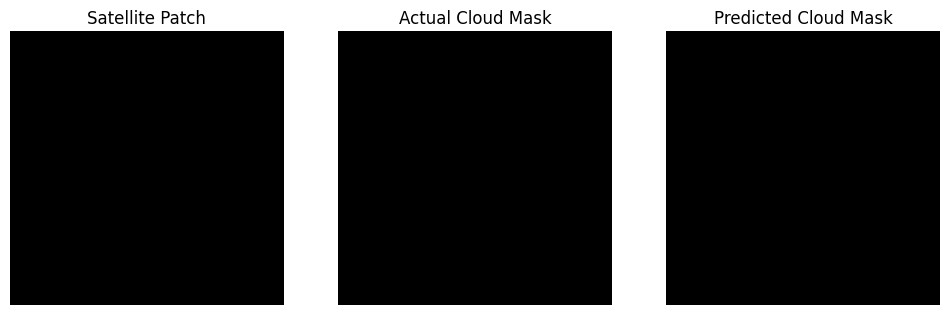

In [23]:
import matplotlib.pyplot as plt
import numpy as np
import os

# 1. Calculate Mean IoU on a validation batch to check your final performance
X_val_sample, y_val_sample = val_gen[0]
preds = (model.predict(X_val_sample) > 0.5).astype(np.float32)

intersection = np.logical_and(y_val_sample, preds).sum()
union = np.logical_or(y_val_sample, preds).sum()
iou_score = intersection / (union + 1e-7)
print(f"Validation Batch IoU Score: {iou_score:.4f}")

# 2. Save the trained model file so Person 3 can use it for the dashboard
os.makedirs('models', exist_ok=True)
model.save('models/unet_cloud_model.keras')
print("Model successfully saved to models/unet_cloud_model.keras")

# 3. Quick visualization (useful for your project documentation)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(X_val_sample[0])
axes[0].set_title("Satellite Patch")
axes[1].imshow(y_val_sample[0].squeeze(), cmap='gray')
axes[1].set_title("Actual Cloud Mask")
axes[2].imshow(preds[0].squeeze(), cmap='gray')
axes[2].set_title("Predicted Cloud Mask")
for ax in axes:
    ax.axis('off')
plt.show()

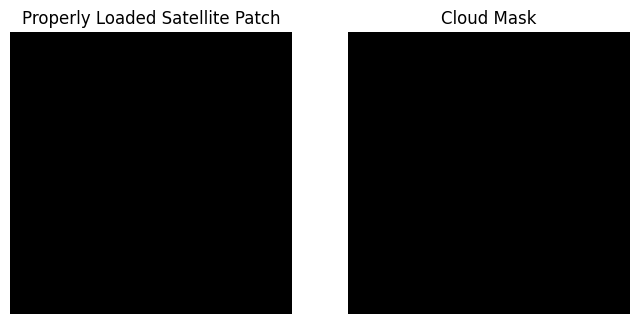

In [24]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load a specific patch using UNCHANGED flag for 16-bit TIFs
sample_img_path = os.path.join(image_dir, all_images[split_idx + 10]) # pick a few indexes down to avoid borders
sample_mask_path = os.path.join(mask_dir, all_masks[split_idx + 10])

img = cv2.imread(sample_img_path, cv2.IMREAD_UNCHANGED)
mask = cv2.imread(sample_mask_path, cv2.IMREAD_UNCHANGED)

if img is not None:
    # Normalize 16-bit satellite data (0 to 65535) to (0 to 1)
    img = cv2.resize(img.astype(np.float32), (256, 256)) / 65535.0
    if len(img.shape) == 2:
        img = np.stack([img, img, img], axis=-1) # Convert single band to 3-channel for display

    mask = cv2.resize(mask.astype(np.float32), (256, 256)) / 255.0

    # Plot the properly scaled image
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    axes[0].imshow(img)
    axes[0].set_title("Properly Loaded Satellite Patch")
    axes[1].imshow(mask, cmap='gray')
    axes[1].set_title("Cloud Mask")
    for ax in axes:
        ax.axis('off')
    plt.show()
else:
    print("Error loading image patch.")

In [25]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


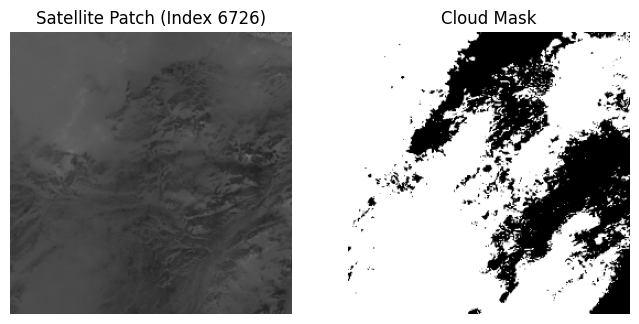

In [26]:
# Automatically search for a patch that isn't completely black
found_idx = 0
for i in range(50):
    test_path = os.path.join(image_dir, all_images[split_idx + i])
    test_img = cv2.imread(test_path, cv2.IMREAD_UNCHANGED)
    if test_img is not None and test_img.max() > 0:
        found_idx = split_idx + i
        break

# Load that specific non-black patch
img = cv2.imread(os.path.join(image_dir, all_images[found_idx]), cv2.IMREAD_UNCHANGED)
mask = cv2.imread(os.path.join(mask_dir, all_masks[found_idx]), cv2.IMREAD_UNCHANGED)

img = cv2.resize(img.astype(np.float32), (256, 256)) / 65535.0
if len(img.shape) == 2:
    img = np.stack([img, img, img], axis=-1)

mask = cv2.resize(mask.astype(np.float32), (256, 256)) / 255.0

# Plot it
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(img)
axes[0].set_title(f"Satellite Patch (Index {found_idx})")
axes[1].imshow(mask, cmap='gray')
axes[1].set_title("Cloud Mask")
for ax in axes:
    ax.axis('off')
plt.show()

In [27]:
!cp -r models /content/drive/MyDrive/